In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../Data/WA_Fn-UseC_-Telco-Customer-Churn.csv")

In [4]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
# Dataset dimensions
print("Shape:", df.shape)

Shape: (7043, 21)


In [4]:
# Missing values
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [5]:
# Duplicate rows
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [6]:
# Basic statistics
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [9]:
# Converting 'TotalCharges' from string to numeric, coercing errors to NaN
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors='coerce')


In [11]:
df["TotalCharges"].isnull().sum()

np.int64(11)

In [12]:
# Total 11 missing values in 'TotalCharges' column. 

In [13]:
# Inspecting rows where TotalCharges became missing

df[df["TotalCharges"].isnull()][["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


In [14]:
df[df["TotalCharges"].isnull()]["tenure"].value_counts()

tenure
0    11
Name: count, dtype: int64

### Handling Missing `TotalCharges`

After converting `TotalCharges` from string to numeric, 11 missing values were identified.

Inspection shows that all 11 affected customers have a tenure of 0 months. These appear to represent newly joined customers for whom no cumulative charges have been recorded yet.

Since these records are valid customers and the missingness has a clear business context, the rows will be retained rather than removed. `TotalCharges` will be set to 0 for these customers, as they have not yet accumulated any tenure-based charges.

### Data Cleaning Decision

The dataset contains 11 missing values in `TotalCharges`. All affected customers have a tenure of 0 months, while their other customer attributes and `Churn` labels are valid.

These records will be retained because they contain useful information for churn analysis. The missing `TotalCharges` values will remain as `NaN` during EDA rather than being assigned an arbitrary value.

In [16]:
# Verifying dataset after cleaning

print("Shape:", df.shape)
print("Missing values:")
print(df.isnull().sum()[df.isnull().sum() > 0])

Shape: (7043, 21)
Missing values:
TotalCharges    11
dtype: int64


In [17]:
# Verifying data types

df.dtypes

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges        float64
Churn                   str
dtype: object

### Exploratory Data Analysis

The objective of this analysis is to identify customer characteristics and service patterns associated with churn.

In [18]:
# Overall churn distribution

df["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [19]:
# Churn percentage

df["Churn"].value_counts(normalize=True).mul(100).round(2)

Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64

### Overall Churn Distribution

The dataset contains 7,043 customers, of whom 1,869 (26.54%) have churned, while 5,174 (73.46%) have remained.

This establishes a baseline churn rate of 26.54% that will be used to compare churn across different customer segments and service characteristics throughout the analysis.

In [33]:
# Churn rate by contract type

contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
).mul(100).round(2)

contract_churn

Churn,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83


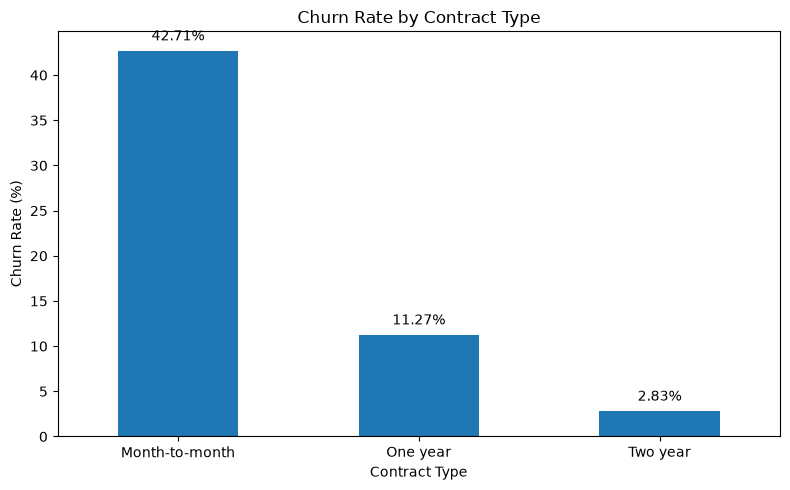

In [34]:
# Visualizing churn rate by contract type

ax = contract_churn["Yes"].plot(
    kind="bar",
    figsize=(8, 5),
    title="Churn Rate by Contract Type",
    ylabel="Churn Rate (%)",
    xlabel="Contract Type"
)

plt.xticks(rotation=0)

# Adding percentage labels above bars
for bar in ax.patches:
    ax.annotate(
        f"{bar.get_height():.2f}%",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha="center",
        va="bottom",
        xytext=(0, 5),
        textcoords="offset points"
    )

plt.tight_layout()
plt.savefig("../Reports/insight_01_contract_type_churn.png", dpi=300, bbox_inches="tight")
plt.show()

### Business Insight 1 — Contract Type

Contract type is strongly associated with customer churn. Month-to-month customers have a churn rate of 42.71%, compared with 11.27% for one-year contracts and only 2.83% for two-year contracts.

This suggests that customers without long-term commitments represent the highest retention risk. The business could consider targeted retention offers or incentives that encourage month-to-month customers to transition to longer-term contracts.

In [31]:
# Churn rate by tenure

tenure_churn = pd.crosstab(
    df["tenure"],
    df["Churn"],
    normalize="index"
).mul(100).round(2)

tenure_churn

Churn,No,Yes
tenure,,
0,100.00,0.00
1,38.01,61.99
2,48.32,51.68
3,53.00,47.00
4,52.84,47.16
...,...,...
68,91.00,9.00
69,91.58,8.42
70,90.76,9.24


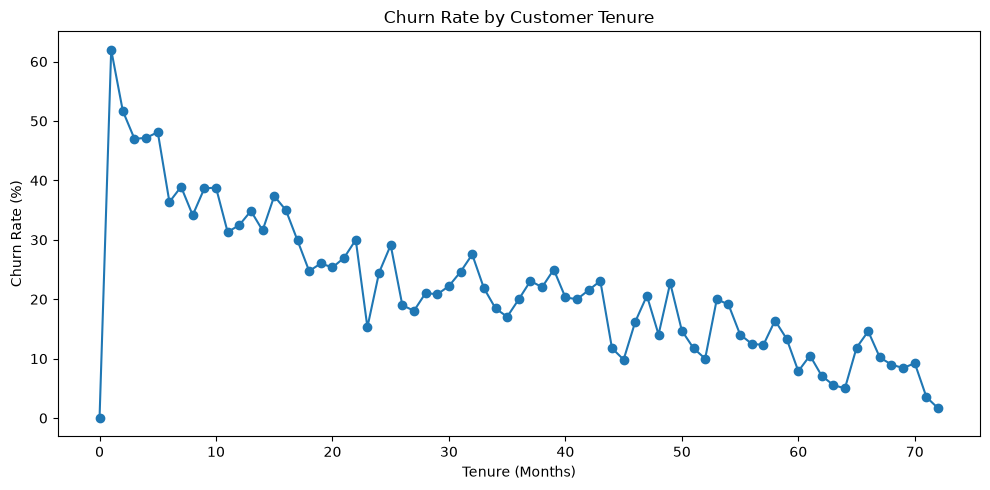

In [32]:
# Plotting churn rate by tenure

ax = tenure_churn["Yes"].plot(
    kind="line",
    figsize=(10, 5),
    marker="o",
    title="Churn Rate by Customer Tenure",
    ylabel="Churn Rate (%)",
    xlabel="Tenure (Months)"
)

plt.tight_layout()
plt.show()

In [28]:
# Grouping customers into meaningful tenure bands

df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=[-1, 6, 12, 24, 48, 72],
    labels=["0-6 months", "7-12 months", "13-24 months", "25-48 months", "49-72 months"]
)

tenure_group_churn = pd.crosstab(
    df["TenureGroup"],
    df["Churn"],
    normalize="index"
).mul(100).round(2)

tenure_group_churn

Churn,No,Yes
TenureGroup,,
0-6 months,47.06,52.94
7-12 months,64.11,35.89
13-24 months,71.29,28.71
25-48 months,79.61,20.39
49-72 months,90.49,9.51


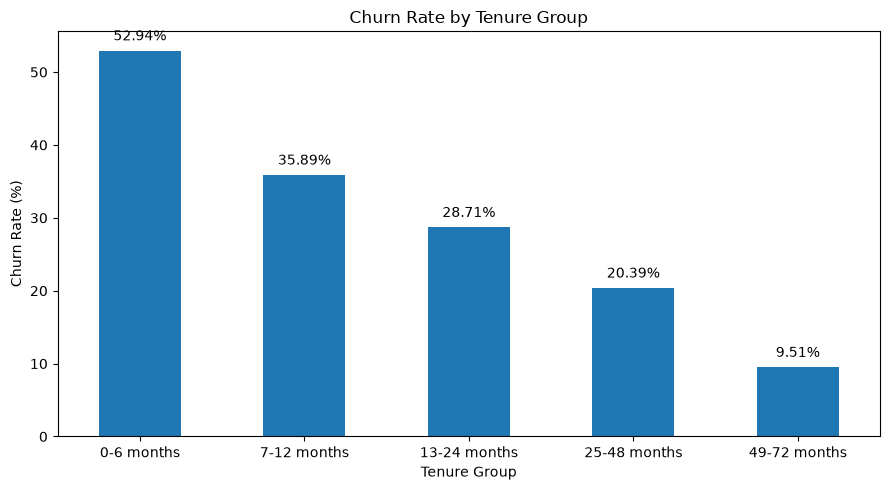

In [29]:
# Visualizing churn rate by tenure group

ax = tenure_group_churn["Yes"].plot(
    kind="bar",
    figsize=(9, 5),
    title="Churn Rate by Tenure Group",
    ylabel="Churn Rate (%)",
    xlabel="Tenure Group"
)

plt.xticks(rotation=0)

# Adding percentage labels
for bar in ax.patches:
    ax.annotate(
        f"{bar.get_height():.2f}%",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha="center",
        va="bottom",
        xytext=(0, 5),
        textcoords="offset points"
    )

plt.tight_layout()
plt.savefig("../Reports/insight_02_tenure_churn.png", dpi=300, bbox_inches="tight")
plt.show()

### Business Insight 2 — Customer Tenure

Churn is heavily concentrated among newer customers. Customers with 0–6 months of tenure have a 52.94% churn rate, which steadily declines to 9.51% among customers with 49–72 months of tenure. This suggests that the early customer lifecycle is the highest-risk period for churn.

In [26]:
# Churn rate by internet service

internet_churn = pd.crosstab(
    df["InternetService"],
    df["Churn"],
    normalize="index"
).mul(100).round(2)

internet_churn

Churn,No,Yes
InternetService,,
DSL,81.04,18.96
Fiber optic,58.11,41.89
No,92.60,7.40


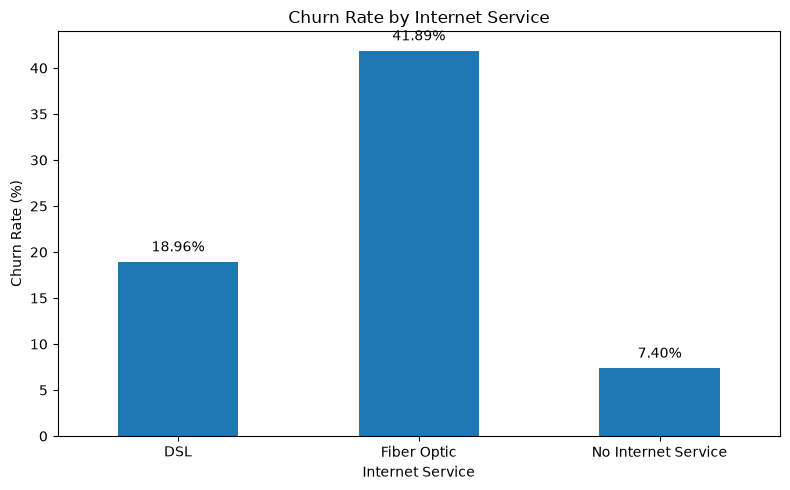

In [27]:
# Visualizing churn rate by internet service

internet_plot = internet_churn["Yes"].copy()

# Improve category labels for presentation
internet_plot.index = internet_plot.index.map({
    "DSL": "DSL",
    "Fiber optic": "Fiber Optic",
    "No": "No Internet Service"
})

ax = internet_plot.plot(
    kind="bar",
    figsize=(8, 5),
    title="Churn Rate by Internet Service",
    ylabel="Churn Rate (%)",
    xlabel="Internet Service"
)

plt.xticks(rotation=0)

# Adding percentage labels
for bar in ax.patches:
    ax.annotate(
        f"{bar.get_height():.2f}%",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha="center",
        va="bottom",
        xytext=(0, 5),
        textcoords="offset points"
    )

plt.tight_layout()
plt.savefig("../Reports/insight_03_internet_service_churn.png", dpi=300, bbox_inches="tight")
plt.show()

### Business Insight 3 — Fiber Optic Customers Show the Highest Churn

Fiber optic customers have the highest churn rate at **41.89%**, compared with **18.96%** for DSL customers and only **7.40%** for customers without internet service.

This indicates a strong association between internet service type and customer churn. The company should investigate whether **pricing, service quality, customer expectations, or competitive alternatives** are contributing to the higher churn among fiber optic customers.

> **Key takeaway:** Fiber optic customers represent a high-priority segment for churn investigation and retention efforts.

In [24]:
# Churn rate by payment method

payment_churn = pd.crosstab(
    df["PaymentMethod"],
    df["Churn"],
    normalize="index"
).mul(100).round(2)

payment_churn

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.29,16.71
Credit card (automatic),84.76,15.24
Electronic check,54.71,45.29
Mailed check,80.89,19.11


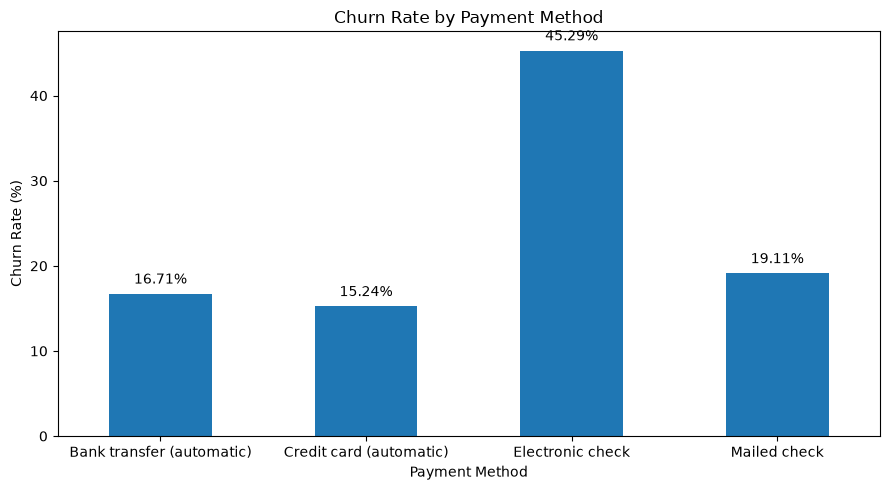

In [25]:
# Visualizing churn rate by payment method

ax = payment_churn["Yes"].plot(
    kind="bar",
    figsize=(9, 5),
    title="Churn Rate by Payment Method",
    ylabel="Churn Rate (%)",
    xlabel="Payment Method"
)

plt.xticks(rotation=0)

# Adding percentage labels
for bar in ax.patches:
    ax.annotate(
        f"{bar.get_height():.2f}%",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha="center",
        va="bottom",
        xytext=(0, 5),
        textcoords="offset points"
    )

plt.tight_layout()
plt.savefig("../Reports/insight_04_payment_method_churn.png", dpi=300, bbox_inches="tight")
plt.show()

### Business Insight 4 — Electronic Check Customers Have the Highest Churn

Customers using **electronic check** have a churn rate of **45.29%**, substantially higher than customers using bank transfer (16.71%), credit card (15.24%), or mailed check (19.11%).

The large difference suggests that **payment method is strongly associated with customer churn**. The company should investigate whether electronic-check customers experience greater billing friction, lower payment convenience, or other characteristics that may contribute to their higher churn.

> **Key takeaway:** Electronic check users represent a high-risk customer segment and should be prioritized for further retention analysis.

In [22]:
# Churn rate by online security

security_churn = pd.crosstab(
    df["OnlineSecurity"],
    df["Churn"],
    normalize="index"
).mul(100).round(2)

security_churn

Churn,No,Yes
OnlineSecurity,,
No,58.23,41.77
No internet service,92.60,7.40
Yes,85.39,14.61


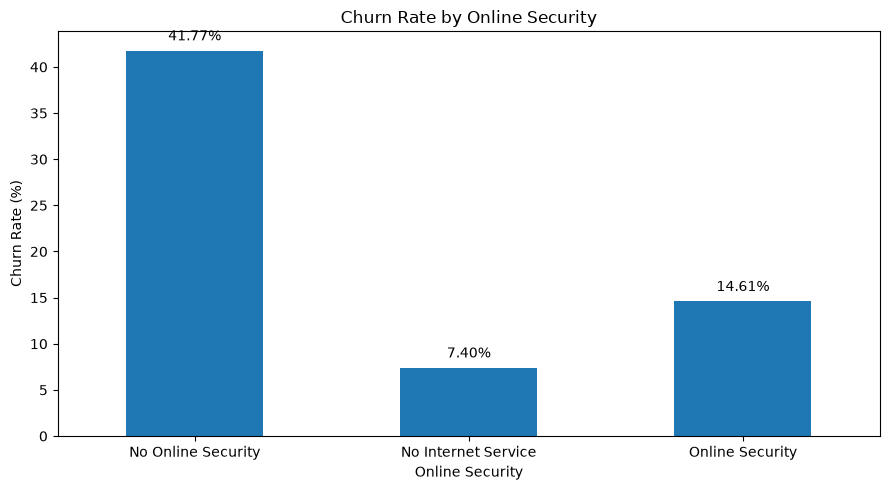

In [23]:
# Visualizing churn rate by online security

security_plot = security_churn["Yes"].copy()


security_plot.index = security_plot.index.map({
    "No": "No Online Security",
    "Yes": "Online Security",
    "No internet service": "No Internet Service"
})

ax = security_plot.plot(
    kind="bar",
    figsize=(9, 5),
    title="Churn Rate by Online Security",
    ylabel="Churn Rate (%)",
    xlabel="Online Security"
)

plt.xticks(rotation=0)

# Adding percentage labels
for bar in ax.patches:
    ax.annotate(
        f"{bar.get_height():.2f}%",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha="center",
        va="bottom",
        xytext=(0, 5),
        textcoords="offset points"
    )

plt.tight_layout()
plt.savefig("../Reports/insight_05_online_security_churn.png", dpi=300, bbox_inches="tight")
plt.show()

### Business Insight 5 — Customers Without Online Security Have Higher Churn

Customers without Online Security have a churn rate of **41.77%**, compared with **14.61%** among customers who subscribe to Online Security.

This shows a strong association between Online Security adoption and customer retention. Customers without the service may represent a less-engaged or higher-risk segment, making them a potential target for **retention campaigns and relevant service bundling**.

> **Key takeaway:** Customers without Online Security should be considered a high-priority segment for further churn investigation and targeted retention strategies.

In [20]:
# Comparing monthly charges by churn status

monthly_charges_churn = df.groupby("Churn")["MonthlyCharges"].agg(
    ["mean", "median"]
).round(2)

monthly_charges_churn

,mean,median
Churn,,
No,61.27,64.43
Yes,74.44,79.65


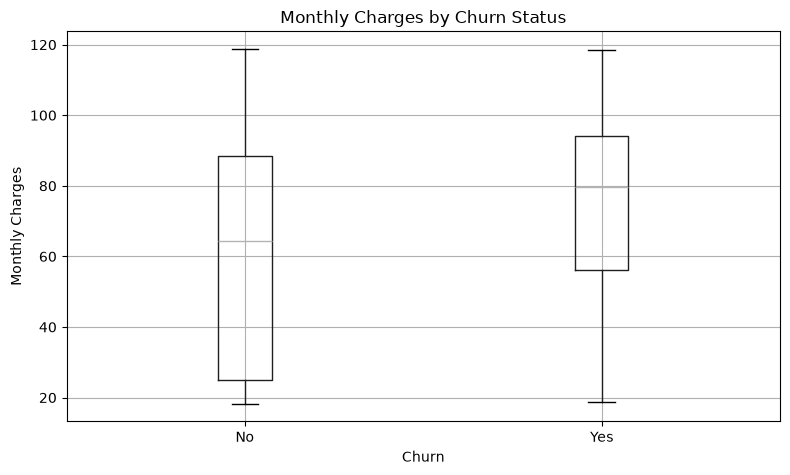

In [21]:
# Visualizing monthly charge distribution by churn status

ax = df.boxplot(
    column="MonthlyCharges",
    by="Churn",
    figsize=(8, 5)
)

plt.title("Monthly Charges by Churn Status")
plt.suptitle("")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")
plt.tight_layout()
plt.savefig("../Reports/insight_06_monthly_charges_churn.png", dpi=300, bbox_inches="tight")
plt.show()

### Business Insight 6 — Higher Monthly Charges Are Associated with Churn

Customers who churned had higher monthly charges, with an average of **$74.44** compared with **$61.27** for customers who stayed. The median monthly charge was also higher among churned customers (**$79.65 vs. $64.43**).

This suggests that customers paying higher monthly charges may represent a higher-risk segment. However, the relationship does not imply that higher charges directly cause churn, as other factors such as **contract type, tenure, and service configuration** may also influence customer decisions.

**Key takeaway:** Higher-paying customers should be examined more closely in retention analysis, particularly in combination with contract and service characteristics.

In [18]:
# Churn rate by dependents

dependents_churn = pd.crosstab(
    df["Dependents"],
    df["Churn"],
    normalize="index"
).mul(100).round(2)

dependents_churn

Churn,No,Yes
Dependents,,
No,68.72,31.28
Yes,84.55,15.45


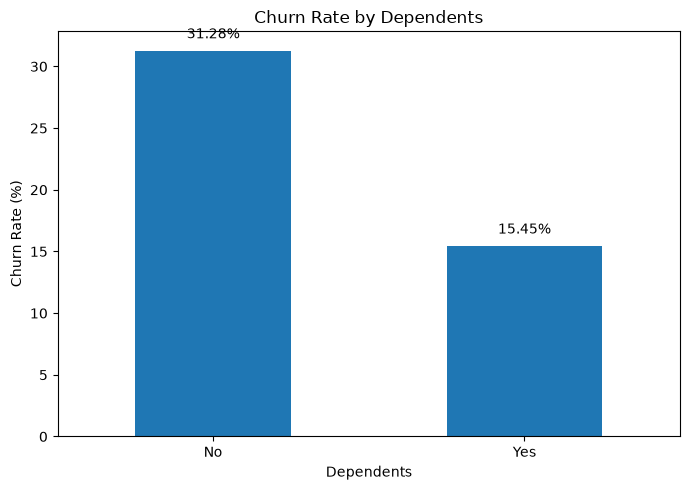

In [19]:
# Visualizing churn rate by dependents

ax = dependents_churn["Yes"].plot(
    kind="bar",
    figsize=(7, 5)
)

plt.title("Churn Rate by Dependents")
plt.ylabel("Churn Rate (%)")
plt.xlabel("Dependents")
plt.xticks(rotation=0)

# Adding percentage labels
for i, value in enumerate(dependents_churn["Yes"]):
    ax.text(i, value + 1, f"{value:.2f}%", ha="center")

plt.tight_layout()
plt.savefig("../Reports/insight_07_dependents_churn.png", dpi=300, bbox_inches="tight")
plt.show()

### Business Insight 7 — Customers Without Dependents Show Higher Churn

Customers without dependents have a churn rate of **31.28%**, compared with **15.45%** among customers with dependents. This represents roughly a **2× higher churn rate** for customers without dependents.

This suggests that customers without dependents may represent a higher-risk segment. However, this relationship should be interpreted alongside other customer characteristics, as dependents alone do not establish the cause of churn.

**Key takeaway:** Customers without dependents should receive additional attention in churn analysis and targeted retention strategies.

In [16]:
# Churn rate by partner status

partner_churn = pd.crosstab(
    df["Partner"],
    df["Churn"],
    normalize="index"
).mul(100).round(2)

partner_churn

Churn,No,Yes
Partner,,
No,67.04,32.96
Yes,80.34,19.66


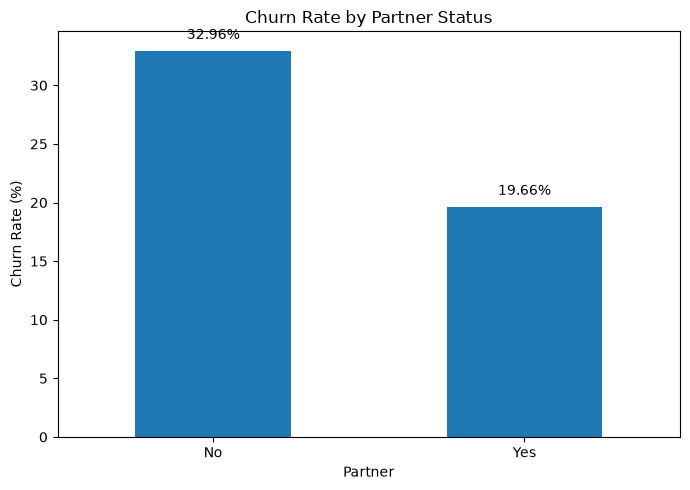

In [17]:
# Visualizing churn rate by partner status

ax = partner_churn["Yes"].plot(
    kind="bar",
    figsize=(7, 5)
)

plt.title("Churn Rate by Partner Status")
plt.ylabel("Churn Rate (%)")
plt.xlabel("Partner")
plt.xticks(rotation=0)

# Adding percentage labels
for i, value in enumerate(partner_churn["Yes"]):
    ax.text(i, value + 1, f"{value:.2f}%", ha="center")

plt.tight_layout()
plt.savefig("../Reports/insight_08_partner_churn.png", dpi=300, bbox_inches="tight")
plt.show()

### Business Insight 8 — Customers Without Partners Show Higher Churn

Customers without partners have a churn rate of **32.96%**, compared with **19.66%** among customers with partners. This represents roughly a **1.7× higher churn rate** for customers without partners.

This suggests that partner status is associated with customer churn and may help identify higher-risk customer segments. However, partner status alone does not establish the cause of churn and should be considered alongside other factors such as **tenure, contract type, and service configuration**.

**Key takeaway:** Customers without partners should receive additional attention in churn analysis and targeted retention strategies.

In [14]:
# Churn rate by senior citizen status

senior_churn = pd.crosstab(
    df["SeniorCitizen"],
    df["Churn"],
    normalize="index"
).mul(100).round(2)

senior_churn

Churn,No,Yes
SeniorCitizen,,
0,76.39,23.61
1,58.32,41.68


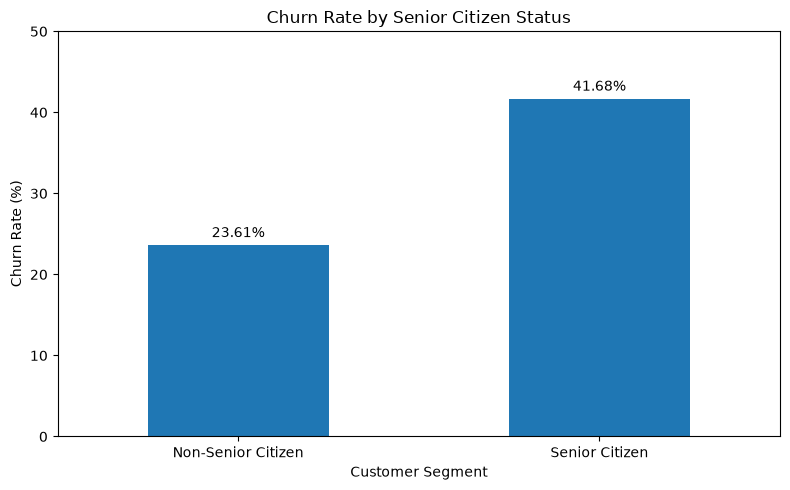

In [15]:
# Visualizing churn rate by senior citizen status

senior_churn_plot = senior_churn["Yes"].copy()

senior_churn_plot.index = ["Non-Senior Citizen", "Senior Citizen"]

ax = senior_churn_plot.plot(
    kind="bar",
    figsize=(8, 5),
    title="Churn Rate by Senior Citizen Status",
    ylabel="Churn Rate (%)",
    xlabel="Customer Segment"
)

for i, value in enumerate(senior_churn_plot):
    ax.text(i, value + 1, f"{value:.2f}%", ha="center")

plt.xticks(rotation=0)
plt.ylim(0, 50)
plt.tight_layout()
plt.savefig("../Reports/insight_09_senior_citizen_churn.png", dpi=300, bbox_inches="tight")
plt.show()

### Business Insight 9 — Senior Citizens Show Higher Churn

Senior citizens have a churn rate of **41.68%**, compared with **23.61%** among non-senior customers. This represents roughly a **1.8× higher churn rate** among senior citizens.

This indicates a strong association between senior citizen status and customer churn. However, senior citizen status alone does not establish the cause of churn and should be evaluated alongside other factors such as **contract type, tenure, monthly charges, and service configuration**.

**Key takeaway:** Senior citizens represent a higher-risk customer segment and may benefit from targeted retention analysis and customer support strategies.

In [10]:
# Churn rate by contract type and internet service

contract_internet_churn = pd.crosstab(
    [df["Contract"], df["InternetService"]],
    df["Churn"],
    normalize="index"
).mul(100).round(2)

contract_internet_churn

Churn                              No    Yes
Contract       InternetService              
Month-to-month DSL              67.78  32.22
               Fiber optic      45.39  54.61
               No               81.11  18.89
One year       DSL              90.70   9.30
               Fiber optic      80.71  19.29
               No               97.53   2.47
Two year       DSL              98.09   1.91
               Fiber optic      92.77   7.23
               No               99.22   0.78

In [11]:
# Customer count for each contract and internet service combination

contract_internet_count = pd.crosstab(
    df["Contract"],
    df["InternetService"]
)

contract_internet_count

InternetService,DSL,Fiber optic,No
Contract,,,
Month-to-month,1223,2128,524
One year,570,539,364
Two year,628,429,638


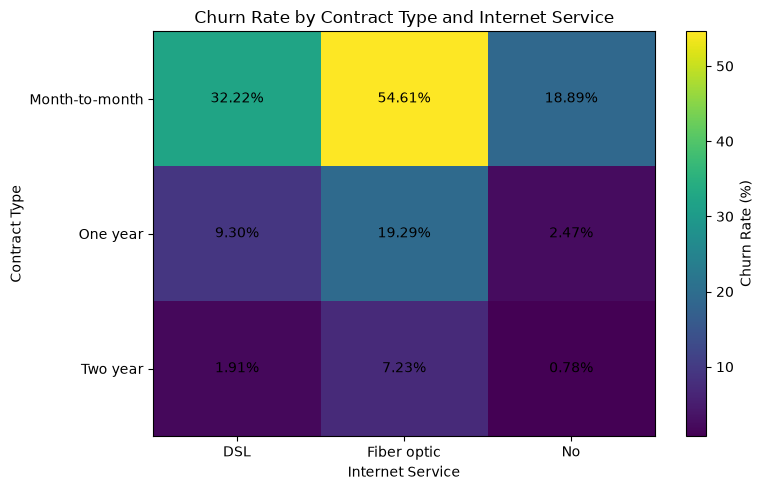

In [12]:
# Visualizing churn rate by contract type and internet service

churn_heatmap = contract_internet_churn["Yes"].unstack()

plt.figure(figsize=(8, 5))

plt.imshow(churn_heatmap, aspect="auto")

plt.xticks(
    range(len(churn_heatmap.columns)),
    churn_heatmap.columns
)

plt.yticks(
    range(len(churn_heatmap.index)),
    churn_heatmap.index
)

plt.title("Churn Rate by Contract Type and Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Contract Type")

for i in range(len(churn_heatmap.index)):
    for j in range(len(churn_heatmap.columns)):
        plt.text(
            j,
            i,
            f"{churn_heatmap.iloc[i, j]:.2f}%",
            ha="center",
            va="center"
        )

plt.colorbar(label="Churn Rate (%)")
plt.tight_layout()
plt.savefig("../Reports/insight_10_contract_internet_churn.png", dpi=300, bbox_inches="tight")
plt.show()

### Business Insight 10 — Month-to-Month Fiber Customers Show Elevated Churn

Customers with **month-to-month contracts and fiber optic service** have the highest observed churn rate at **54.61%**, compared with **32.22%** for month-to-month DSL customers and **18.89%** for month-to-month customers without internet service.

The relationship becomes even more notable when comparing fiber optic customers across contract types: churn falls from **54.61%** for month-to-month contracts to **19.29%** for one-year contracts and **7.23%** for two-year contracts.

This suggests that **contract commitment and internet service type interact in their association with churn**. However, these results do not establish causation, and other factors may contribute to the observed differences.

**Key takeaway:** Month-to-month fiber optic customers represent a particularly high-risk segment and should be prioritized for deeper analysis and targeted retention strategies.